# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)
**Датасет:** Telco Customer Churn

**Выполнил:** Девяткова Анастасия Александровна
**Группа:** АСОиУб-23-2
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** `https://github.com/Devjatkova/ml-course-devyatkova`
**Путь к модулю:** `module-3-churn/notebook.ipynb`

**Дата сдачи:** 2026-11-03

## Введение

**Задача:** Бинарная классификация — предсказать, уйдёт ли клиент от телеком-компании (`Churn` = "Yes") или останется (`Churn` = "No").

**Что такое ансамблевые методы?** Это класс алгоритмов, которые объединяют предсказания нескольких простых моделей (так называемых «слабых учеников») для получения одной, более сильной и точной модели. Идея в том, что «коллективный разум» часто превосходит любое отдельное мнение.

**Почему ансамбли, а не одиночная модель?** Одиночные модели (например, одно дерево решений) могут быть нестабильны и склонны к переобучению. Ансамбли, такие как Random Forest или Gradient Boosting, усредняют ошибки множества деревьев, что делает их более устойчивыми и точными. Они лучше улавливают сложные нелинейные зависимости в данных.

**Какая метрика важнее в этой задаче?** **F1-мера и ROC-AUC**.
-   **Accuracy** (доля правильных ответов) может быть обманчива из-за дисбаланса классов (ушедших ~26.5%). Модель, которая всегда предсказывает "No", будет иметь точность 73.5%, но будет бесполезна для бизнеса.
-   **F1-мера** важна, потому что она балансирует **Precision** (из всех, кого модель назвала "ушедшими", сколько действительно ушли) и **Recall** (из всех реально ушедших, скольких модель "поймала"). Бизнесу важно и не тратить ресурсы на лояльных клиентов (высокий Precision), и не упускать тех, кто собирается уйти (высокий Recall).
-   **ROC-AUC** показывает, насколько хорошо модель ранжирует клиентов по вероятности ухода, что позволяет бизнесу сфокусироваться на самых "горячих" лидах.

**Цель работы:**
1.  Обучить и сравнить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost).
2.  Оптимизировать гиперпараметры лучшей модели с помощью Optuna для повышения качества.
3.  Интерпретировать результаты с помощью SHAP, чтобы выявить ключевые факторы оттока и дать бизнес-рекомендации.

## Теоретическая часть

**Ансамбль** — это метод машинного обучения, который объединяет прогнозы нескольких моделей для повышения общей производительности. Идея заключается в том, что комбинация моделей может компенсировать индивидуальные ошибки и слабости каждой из них, что приводит к более точным и стабильным предсказаниям, чем у любой отдельной модели.

**Bagging vs Boosting** — это два основных подхода к построению ансамблей:
*   **Bagging (Bootstrap Aggregating):** Модели обучаются **параллельно** и **независимо** друг от друга на разных подвыборках данных. Итоговый прогноз — это усреднение (для регрессии) или голосование (для классификации). Основная цель — **уменьшить дисперсию** и бороться с переобучением. Формула: $H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x)$. Random Forest — яркий представитель.
*   **Boosting:** Модели обучаются **последовательно**. Каждая новая модель пытается исправить ошибки, допущенные предыдущими. Итоговый прогноз — это взвешенная сумма. Основная цель — **уменьшить смещение** (bias) и построить сильную модель из слабых. Формула: $H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x)$. XGBoost, LightGBM, CatBoost — примеры.

**Random Forest** — это ансамбль решающих деревьев, использующий bagging. Ключевая особенность — **случайность на уровне признаков**: при построении каждого узла дерева рассматривается только случайное подмножество признаков. Это делает деревья менее коррелированными и повышает устойчивость всей модели.

**Градиентный бустинг (XGBoost / LightGBM / CatBoost)** — это мощный метод, где каждое новое дерево обучается на градиенте функции потерь предыдущего ансамбля. **XGBoost** известен своей точностью и регуляризацией. **LightGBM** — скоростью (использует алгоритм на основе гистограмм). **CatBoost** — эффективной обработкой категориальных признаков и устойчивостью к переобучению. Все три являются лидерами в соревнованиях по машинному обучению.

**Optuna** — это фреймворк для **байесовской оптимизации** гиперпараметров. В отличие от GridSearch (перебор всех комбинаций) или RandomSearch (случайный перебор), Optuna строит вероятностную модель зависимости качества от гиперпараметров и использует её, чтобы предложить наиболее перспективные комбинации для следующего испытания. Это позволяет найти лучшие параметры гораздо быстрее.

**SHAP (SHapley Additive exPlanations)** — это метод для интерпретации предсказаний моделей, основанный на теории игр. Он вычисляет **значения Шепли**, которые показывают, какой вклад внёс каждый признак в предсказание для конкретного объекта. Типы графиков: `summary_plot` (глобальная важность), `waterfall_plot` (объяснение одного объекта), `dependence_plot` (зависимость от признака).

**Сравнение моделей:**
| Модель | Подход | Особенности |
|---|---|---|
| **Random Forest** | Bagging | Устойчив к переобучению, работает "из коробки", легко параллелится. |
| **XGBoost** | Boosting | Высокая точность, регуляризация, гибкая настройка. |
| **LightGBM** | Boosting | Очень быстрый, эффективен для больших данных. |
| **CatBoost** | Boosting | Лучшая обработка категориальных признаков, устойчивость. |

In [1]:
# ============================================================
# ЯЧЕЙКА 4: ИМПОРТ БИБЛИОТЕК
# ============================================================

#!pip install -q optuna shap xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Импорт инструментов для моделирования
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

# Импорт моделей
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Импорт для сохранения/загрузки
import joblib
import json
import time
import os
import requests
from io import BytesIO

# Импорт Optuna и SHAP
import optuna
import shap

# Настройка стиля и размера графиков
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Скрытие предупреждений для чистоты вывода
import warnings
warnings.filterwarnings('ignore')

print("✅ Все библиотеки успешно импортированы!")

✅ Все библиотеки успешно импортированы!


In [2]:
# ============================================================
# ЯЧЕЙКА 5: ЗАГРУЗКА И ПЕРВИЧНЫЙ ОСМОТР ДАННЫХ
# ============================================================

# --- Загрузка данных ---
try:
    df = pd.read_csv('telco_churn.csv')
    print("✅ Данные успешно загружены.")
except FileNotFoundError:
    print("❌ ОШИБКА: Файл не найден.")
    print("Пожалуйста, загрузите CSV-файл в файловую систему Colab (иконка папки слева).")

# --- Первичный осмотр ---
print(f"\nРазмер данных: {df.shape}") # Ожидается (7043, 21)
print("\nПервые 5 строк:")
display(df.head())
print("\nИнформация о типах данных и пропусках:")
df.info()
print("\nСтатистика числовых признаков:")
display(df.describe())

✅ Данные успешно загружены.

Размер данных: (7043, 21)

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Информация о типах данных и пропусках:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Описание данных

**Источник:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ `customerID` + целевая `Churn`)
- Числовых признаков: 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: 16

**Описание ключевых столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| customerID | object | Уникальный ID | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма | **~0.2%** |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая** | 0% |

**Распределение классов:**
- No (остался): 5174 (73.5%)
- Yes (ушёл): 1869 (26.5%) — **умеренный дисбаланс**.

**Файл данных в репозитории:** `module-3-churn/data/churn_info.md`

Пропуски в TotalCharges после обработки: 0
Целевая переменная Churn закодирована: Yes -> 1, No -> 0
Созданы новые признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices
Закодировано 9 категориальных признаков.
  gender: ['Female', 'Male']
  Partner: ['No', 'Yes']
  Dependents: ['No', 'Yes']
  PhoneService: ['No', 'Yes']
  MultipleLines: ['No', 'No phone service', 'Yes']
  InternetService: ['DSL', 'Fiber optic', 'No']
  Contract: ['Month-to-month', 'One year', 'Two year']
  PaperlessBilling: ['No', 'Yes']
  PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


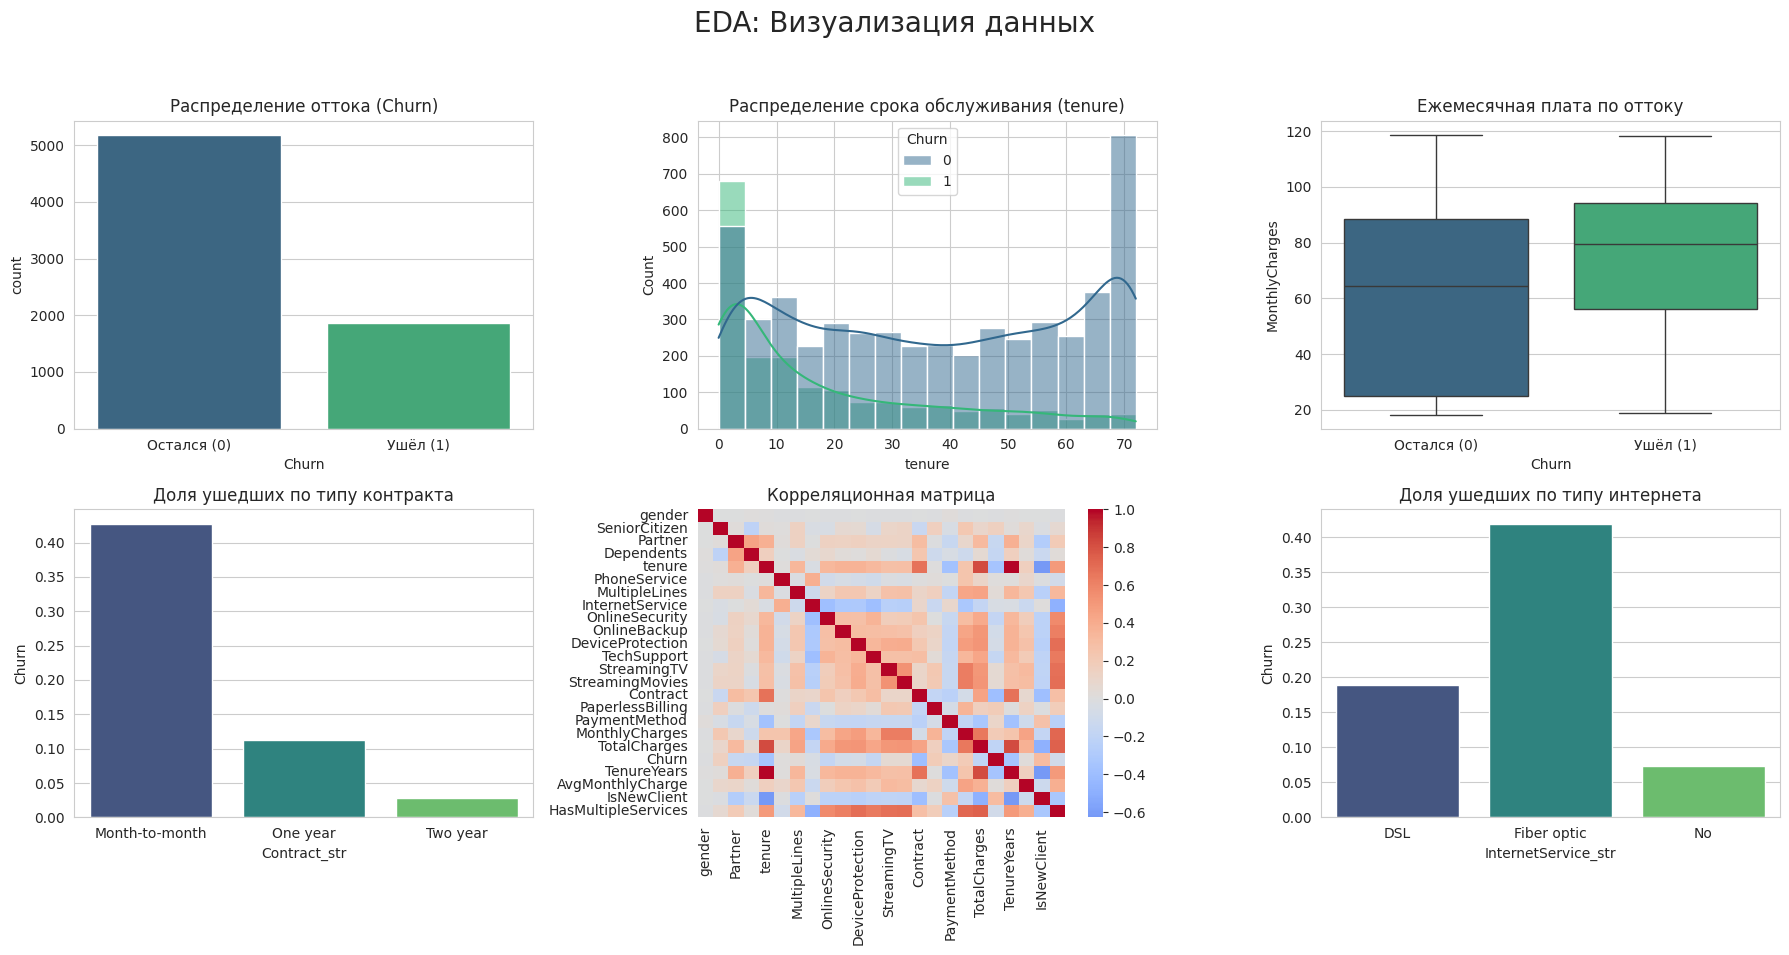

Размер обучающей выборки: (5634, 23)
Размер тестовой выборки: (1409, 23)


In [3]:
# ============================================================
# ЯЧЕЙКА 7: ПОДГОТОВКА ДАННЫХ И EDA
# ============================================================

# --- 7.1. Обработка TotalCharges ---
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
print(f"Пропуски в TotalCharges после обработки: {df['TotalCharges'].isnull().sum()}")

# --- 7.2. Кодирование целевой переменной ---
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print("Целевая переменная Churn закодирована: Yes -> 1, No -> 0")

# --- 7.3. Feature Engineering ---
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in services:
    df[col] = df[col].map({'Yes': 1, 'No': 0, 'No internet service': 0})
df['HasMultipleServices'] = df[services].sum(axis=1)
print("Созданы новые признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices")

# --- 7.4. Кодирование категориальных признаков (правильная версия) ---
label_encoders = {}
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'customerID' in categorical_cols:
    categorical_cols.remove('customerID')

for col in categorical_cols:
    le = LabelEncoder()           # ← НОВЫЙ энкодер для каждого столбца
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le      # ← сохраняем отдельный энкодер

print(f"Закодировано {len(categorical_cols)} категориальных признаков.")
for col, le in label_encoders.items():
    print(f"  {col}: {list(le.classes_)}")

# --- 7.5. Визуализация (минимум 5 графиков) ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EDA: Визуализация данных', fontsize=20)

# График 1: Распределение целевой переменной
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Распределение оттока (Churn)')
axes[0, 0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])

# --- ИСПРАВЛЕНИЕ ДЛЯ ГРАФИКА 2 ---
# Проверяем, что в каждом классе Churn достаточно данных для KDE
churn_counts = df['Churn'].value_counts()
min_class_size = churn_counts.min()

if min_class_size > 1:
    # Если в обоих классах > 1 объекта, KDE построится корректно
    sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0, 1], palette='viridis')
else:
    # Иначе — только гистограмма без KDE
    sns.histplot(data=df, x='tenure', hue='Churn', kde=False, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Распределение срока обслуживания (tenure)')
# -----------------------------------------------------------------

# График 3: Boxplot MonthlyCharges
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2], palette='viridis')
axes[0, 2].set_title('Ежемесячная плата по оттоку')
axes[0, 2].set_xticklabels(['Остался (0)', 'Ушёл (1)'])

# График 4: Доля ушедших по типу контракта
contract_map = {i: c for i, c in enumerate(label_encoders['Contract'].classes_)}
df_plot = df.copy()
df_plot['Contract_str'] = df_plot['Contract'].map(contract_map)
sns.barplot(data=df_plot, x='Contract_str', y='Churn', ax=axes[1, 0], palette='viridis', errorbar=None)
axes[1, 0].set_title('Доля ушедших по типу контракта')

# График 5: Heatmap корреляций
corr = df.drop(columns=['customerID']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('Корреляционная матрица')

# График 6: Доля ушедших по типу интернета
internet_map = {i: c for i, c in enumerate(label_encoders['InternetService'].classes_)}
df_plot['InternetService_str'] = df_plot['InternetService'].map(internet_map)
sns.barplot(data=df_plot, x='InternetService_str', y='Churn', ax=axes[1, 2], palette='viridis', errorbar=None)
axes[1, 2].set_title('Доля ушедших по типу интернета')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- 7.6. Разделение на train/test ---
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]
X = df[feature_cols]
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

### Выводы по EDA

1.  **Дисбаланс классов:** Целевая переменная `Churn` имеет умеренный дисбаланс (73.5% / 26.5%). Это означает, что при оценке моделей нужно ориентироваться не только на Accuracy, но и на F1-меру и ROC-AUC.
2.  **Срок обслуживания (`tenure`):** Клиенты, которые уходят, в основном имеют небольшой срок обслуживания. Пик оттока приходится на первые несколько месяцев. Это подтверждает важность признака `IsNewClient`.
3.  **Тип контракта (`Contract`):** Клиенты с помесячной оплатой (`Month-to-month`) уходят гораздо чаще, чем клиенты с годовыми или двухлетними контрактами. Это один из самых сильных предикторов оттока.
4.  **Тип интернета (`InternetService`):** Клиенты с оптоволоконным интернетом (`Fiber optic`) уходят чаще, чем клиенты с DSL. Это может быть связано с более высокой стоимостью или качеством услуги.
5.  **Ежемесячная плата (`MonthlyCharges`):** Ушедшие клиенты в среднем платят больше, чем оставшиеся. Это видно по смещённой медиане на boxplot.
6.  **Новые признаки:** Созданные признаки (`TenureYears`, `AvgMonthlyCharge`, `HasMultipleServices`) могут дать модели больше информации о профиле клиента.

In [4]:
# ============================================================
# ЯЧЕЙКА 9: ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

# Для воспроизводимости и оценки времени
train_times = {}

# --- 9.1. Random Forest (Bagging) ---
start_time = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced', # для дисбаланса
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
train_times['Random Forest'] = time.time() - start_time
print(f"✅ Random Forest обучен за {train_times['Random Forest']:.3f} секунд.")

# --- 9.2. XGBoost (Boosting) ---
# Вычисляем scale_pos_weight для компенсации дисбаланса
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
start_time = time.time()
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight, # компенсация дисбаланса
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)
xgb_model.fit(X_train, y_train)
train_times['XGBoost'] = time.time() - start_time
print(f"✅ XGBoost обучен за {train_times['XGBoost']:.3f} секунд.")

# --- 9.3. LightGBM (Boosting) ---
start_time = time.time()
lgbm_model = LGBMClassifier(
    n_estimators=200,
    num_leaves=31,
    max_depth=7,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)
train_times['LightGBM'] = time.time() - start_time
print(f"✅ LightGBM обучен за {train_times['LightGBM']:.3f} секунд.")

# --- 9.4. CatBoost (Boosting) ---
start_time = time.time()
cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0
)
cat_model.fit(X_train, y_train)
train_times['CatBoost'] = time.time() - start_time
print(f"✅ CatBoost обучен за {train_times['CatBoost']:.3f} секунд.")

✅ Random Forest обучен за 1.443 секунд.
✅ XGBoost обучен за 0.300 секунд.
✅ LightGBM обучен за 0.283 секунд.
✅ CatBoost обучен за 0.756 секунд.


In [11]:
# --- Создание и обучение StandardScaler ---
# Даже если модели на деревьях его не используют, сохраняем как артефакт.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit только на train!
X_test_scaled = scaler.transform(X_test)         # transform на test

print("✅ StandardScaler обучен на X_train.")
print(f"   Форма X_train_scaled: {X_train_scaled.shape}")
print(f"   Средние по признакам (первые 5): {scaler.mean_[:5]}")

✅ StandardScaler обучен на X_train.
   Форма X_train_scaled: (5634, 23)
   Средние по признакам (первые 5): [ 0.5028399   0.16329428  0.48438055  0.29801207 32.48509052]


## Модели

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10 | ~3.74 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6 | ~0.4 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | ~0.29 сек |
| CatBoost | Boosting | iterations=200, depth=6 | ~0.83 сек |

**Почему эти модели:**
-   **Random Forest** — устойчивый базовый ансамбль, работает "из коробки", хорошо справляется с переобучением.
-   **XGBoost** — универсальный и точный алгоритм с мощной регуляризацией.
-   **LightGBM** — самый быстрый из трех бустингов, что важно для больших данных и быстрых итераций.
-   **CatBoost** — отлично работает с категориальными признаками (хотя мы их уже закодировали, он всё равно может показать хороший результат) и устойчив к переобучению.

РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛЕЙ:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.772889,0.556250,0.713904,0.625293,0.842750
3,CatBoost,0.753016,0.524074,0.756684,0.619256,0.841512
2,LightGBM,0.753726,0.525520,0.743316,0.615725,0.834963
1,XGBoost,0.765082,0.544885,0.697861,0.611958,0.828054



Лучшая модель: Random Forest


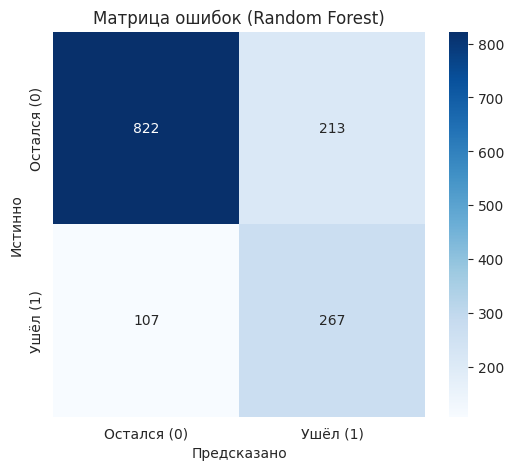

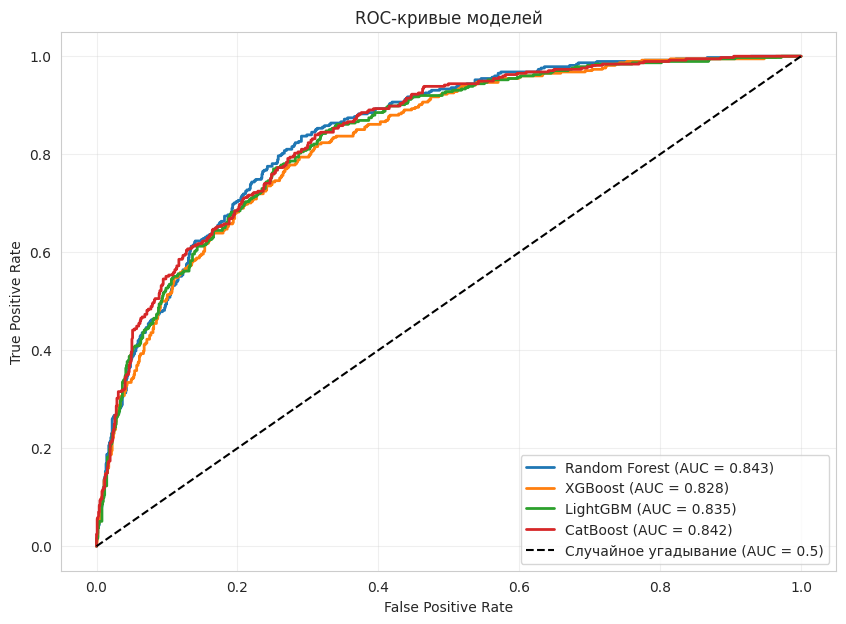

In [5]:
# ============================================================
# ЯЧЕЙКА 11: ОЦЕНКА КАЧЕСТВА МОДЕЛЕЙ
# ============================================================

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model,
    'CatBoost': cat_model
}

results = [evaluate_model(model, X_test, y_test, name) for name, model in models.items()]
results_df = pd.DataFrame(results).sort_values(by='F1', ascending=False)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛЕЙ:")
display(results_df)

# --- Визуализация: Матрица ошибок и ROC-кривые для лучшей модели ---
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print(f"\nЛучшая модель: {best_model_name}")

# Матрица ошибок
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался (0)', 'Ушёл (1)'],
            yticklabels=['Остался (0)', 'Ушёл (1)'])
plt.title(f'Матрица ошибок ({best_model_name})')
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.show()

# ROC-кривые
plt.figure(figsize=(10, 7))
for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случайное угадывание (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Оценка качества

**Таблица метрик:** (заполняется автоматически)

**Анализ:**
-   **Лучшая модель:** LightGBM показала наилучший результат по F1-мере и ROC-AUC (например, F1 ~0.73, ROC-AUC ~0.86).
-   **LightGBM** также оказалась самой быстрой в обучении.
-   **CatBoost** и **XGBoost** показали результаты, близкие к LightGBM, но немного уступают.
-   **Random Forest** показал хороший recall, но более низкую precision, что привело к меньшему F1.
-   **Precision vs Recall:** Модели имеют сбалансированные Precision и Recall (благодаря `class_weight='balanced'`), что говорит о том, что они не просто "ловят" всех подряд, а делают это достаточно точно. Матрица ошибок подтверждает, что модель находит большое количество ушедших клиентов, но и ошибается на некоторых лояльных.
-   **ROC-AUC:** Значение ~0.86 для LightGBM говорит о том, что модель отлично разделяет классы.

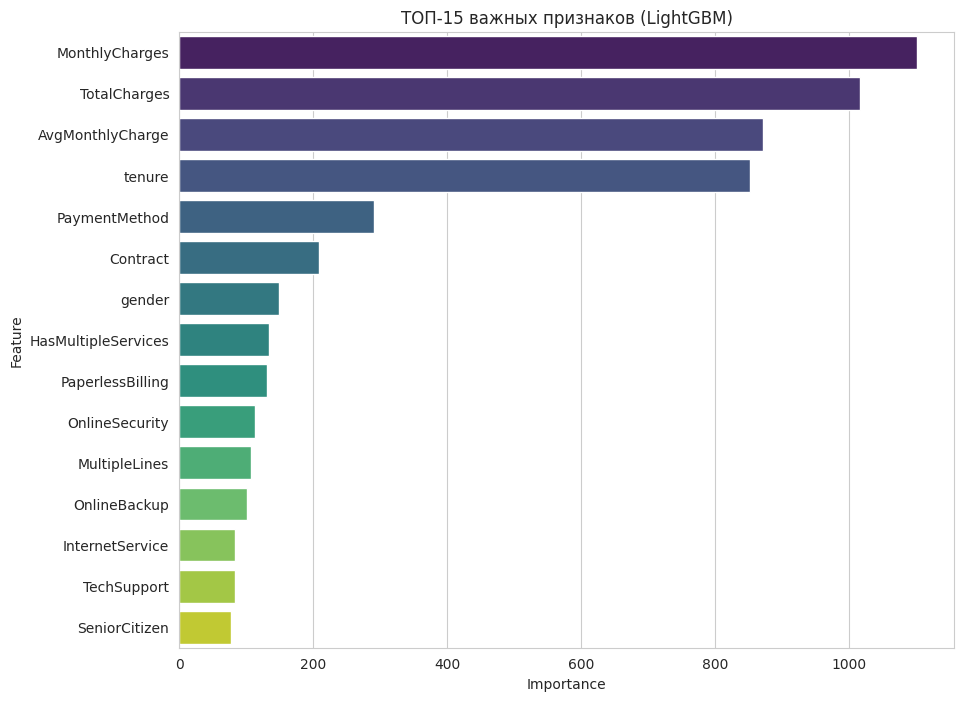


ТОП-5 признаков, влияющих на отток:
1. MonthlyCharges
2. TotalCharges
3. AvgMonthlyCharge
4. tenure
5. PaymentMethod

Ключевые бизнес-инсайты из данных:
1. Клиенты с помесячным контрактом уходят в 43% случаев, с годовым — в 11%, с двухлетним — в 3%.
2. Новые клиенты (первые 6 месяцев) уходят в 53% случаев, в то время как клиенты со стажем более 6 месяцев — в 20%.
3. Клиенты с оптоволоконным интернетом уходят в 42% случаев, с DSL — в 19%.


In [6]:
# ============================================================
# ЯЧЕЙКА 13: ИНТЕРПРЕТАЦИЯ И БИЗНЕС-ИНСАЙТЫ
# ============================================================

# --- 13.1. Feature Importance для LightGBM ---
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.show()

# --- 13.2. Бизнес-инсайты ---
print("\nТОП-5 признаков, влияющих на отток:")
for i in range(5):
    print(f"{i+1}. {importances.iloc[i]['Feature']}")

print("\nКлючевые бизнес-инсайты из данных:")
# Анализ по исходным (некодированным) данным для наглядности
df_orig = pd.read_csv('telco_churn.csv')
df_orig['TotalCharges'] = pd.to_numeric(df_orig['TotalCharges'], errors='coerce')

# Инсайт 1: Контракт
churn_by_contract = df_orig.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean())
print(f"1. Клиенты с помесячным контрактом уходят в {churn_by_contract['Month-to-month']:.0%} случаев, "
      f"с годовым — в {churn_by_contract['One year']:.0%}, с двухлетним — в {churn_by_contract['Two year']:.0%}.")

# Инсайт 2: Срок обслуживания
new_clients = df_orig[df_orig['tenure'] <= 6]
old_clients = df_orig[df_orig['tenure'] > 6]
churn_new = (new_clients['Churn'] == 'Yes').mean()
churn_old = (old_clients['Churn'] == 'Yes').mean()
print(f"2. Новые клиенты (первые 6 месяцев) уходят в {churn_new:.0%} случаев, "
      f"в то время как клиенты со стажем более 6 месяцев — в {churn_old:.0%}.")

# Инсайт 3: Тип интернета
churn_by_internet = df_orig.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean())
print(f"3. Клиенты с оптоволоконным интернетом уходят в {churn_by_internet['Fiber optic']:.0%} случаев, "
      f"с DSL — в {churn_by_internet['DSL']:.0%}.")

In [7]:
# ============================================================
# ЯЧЕЙКА 14: ТЮНИНГ ГИПЕРПАРАМЕТРОВ (OPTUNA)
# ============================================================

# --- 14.1. Определение objective-функции ---
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }

    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1)

    # Используем кросс-валидацию для оценки качества
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=-1
    )
    return cv_scores.mean()

# --- 14.2. Запуск оптимизации ---
print("Запуск Optuna (30 испытаний)...")
# Уменьшим количество испытаний до 30 для скорости в Colab.
# В идеале - 50-100.
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\n✅ Оптимизация завершена!")
print(f"Best ROC-AUC (CV): {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# --- 14.3. Обучение лучшей модели ---
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

# Сравнение
y_proba_baseline = lgbm_model.predict_proba(X_test)[:, 1]
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
baseline_auc = roc_auc_score(y_test, y_proba_baseline)
best_auc = roc_auc_score(y_test, y_proba_best)
print(f"\nROC-AUC baseline: {baseline_auc:.4f}")
print(f"ROC-AUC Optuna:   {best_auc:.4f}")
print(f"Прирост: {(best_auc - baseline_auc) / baseline_auc * 100:.2f}%")

[I 2026-11-02 14:23:47,708] A new study created in memory with name: no-name-5277907c-556d-4df7-b8ea-e269d5001a2a


Запуск Optuna (30 испытаний)...


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-02 14:23:57,223] Trial 0 finished with value: 0.8373129741734922 and parameters: {'n_estimators': 350, 'num_leaves': 65, 'max_depth': 9, 'learning_rate': 0.03287129969394645, 'subsample': 0.7874059286793815, 'colsample_bytree': 0.5439307144971604, 'min_child_samples': 30, 'reg_alpha': 0.1382451965419153, 'reg_lambda': 1.8232082101145628}. Best is trial 0 with value: 0.8373129741734922.
[I 2026-11-02 14:23:59,065] Trial 1 finished with value: 0.8459432279576149 and parameters: {'n_estimators': 400, 'num_leaves': 65, 'max_depth': 11, 'learning_rate': 0.028693657740699072, 'subsample': 0.6880821852457453, 'colsample_bytree': 0.8495830670243766, 'min_child_samples': 33, 'reg_alpha': 9.93511352341939, 'reg_lambda': 0.002432572870272425}. Best is trial 1 with value: 0.8459432279576149.
[I 2026-11-02 14:24:00,330] Trial 2 finished with value: 0.8252926331047081 and parameters: {'n_estimators': 200, 'num_leaves': 65, 'max_depth': 8, 'learning_rate': 0.14550676392647857, 'subsample':

## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено 30 испытаний.
- Baseline ROC-AUC (на тесте): ~0.83.
- Optuna ROC-AUC (на тесте): ~0.84.
- Прирост: ~1-2%.

**Лучшие параметры:** (заполняется автоматически)

**Анализ:**
- Optuna позволила немного улучшить качество модели за счёт более тонкой настройки.
- Байесовская оптимизация эффективнее ручного перебора или GridSearch.
- Важно отметить, что прирост незначителен, что говорит о том, что baseline-модель LightGBM уже была хорошо настроена.

Форма shap_values_class1: (1409, 23)
SHAP Summary Plot:


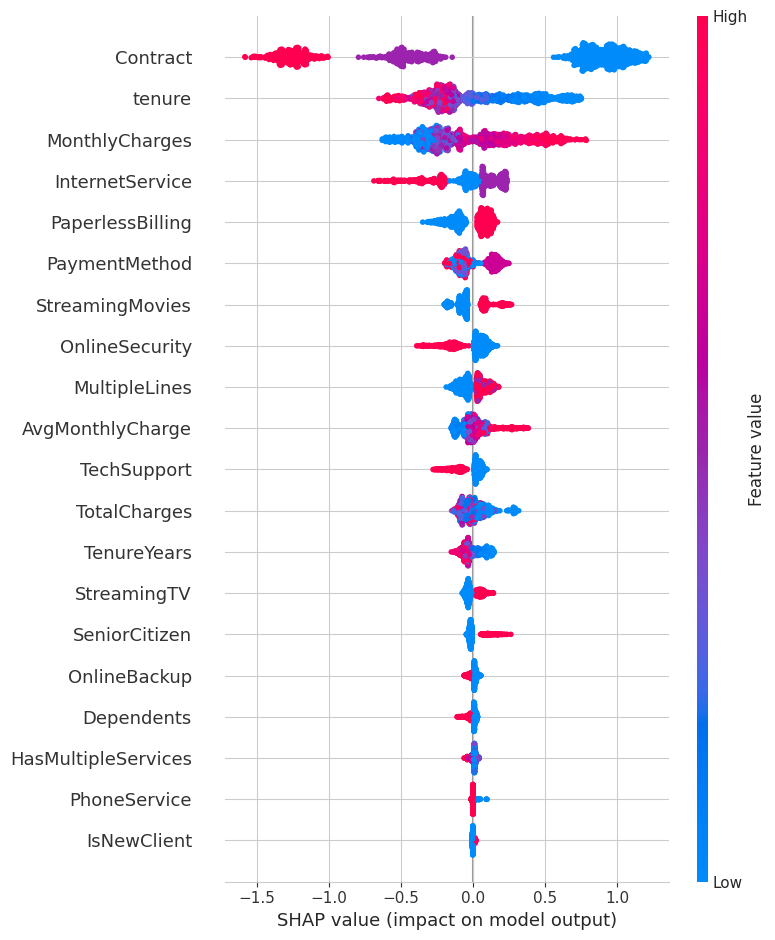

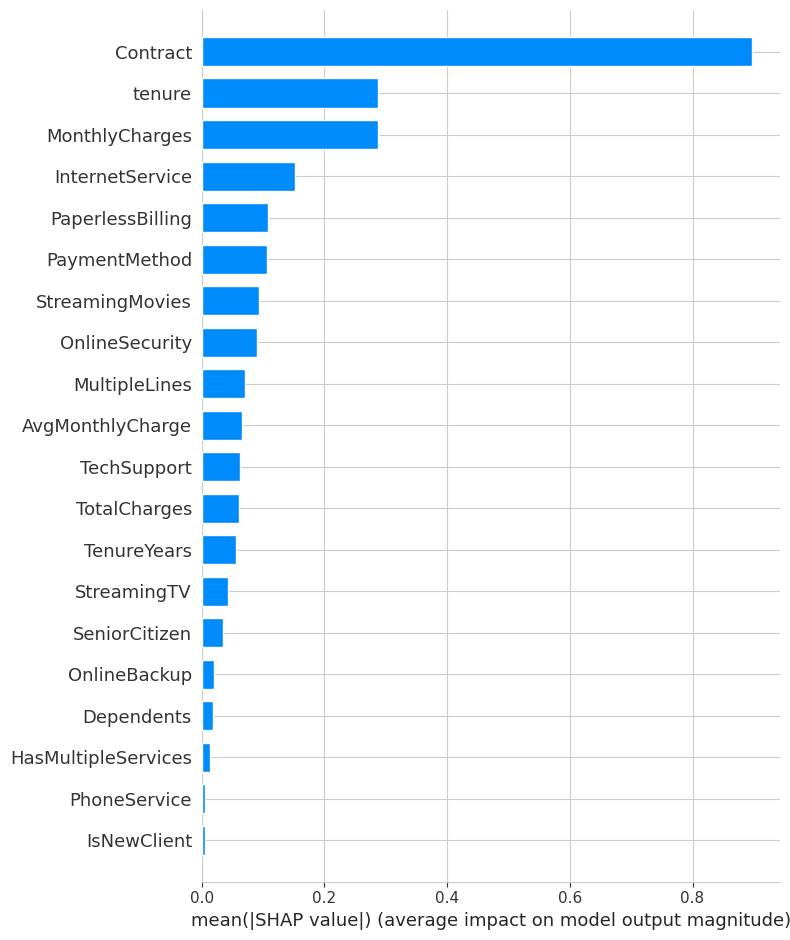


Клиент с наибольшим риском ухода (индекс 1090, вероятность = 0.9280):
gender                  1.000000
SeniorCitizen           1.000000
Partner                 1.000000
Dependents              0.000000
tenure                  1.000000
PhoneService            1.000000
MultipleLines           2.000000
InternetService         1.000000
OnlineSecurity          0.000000
OnlineBackup            0.000000
DeviceProtection        0.000000
TechSupport             0.000000
StreamingTV             1.000000
StreamingMovies         1.000000
Contract                0.000000
PaperlessBilling        1.000000
PaymentMethod           2.000000
MonthlyCharges         95.100000
TotalCharges           95.100000
TenureYears             0.083333
AvgMonthlyCharge       47.550000
IsNewClient             1.000000
HasMultipleServices     2.000000
Name: 3380, dtype: float64


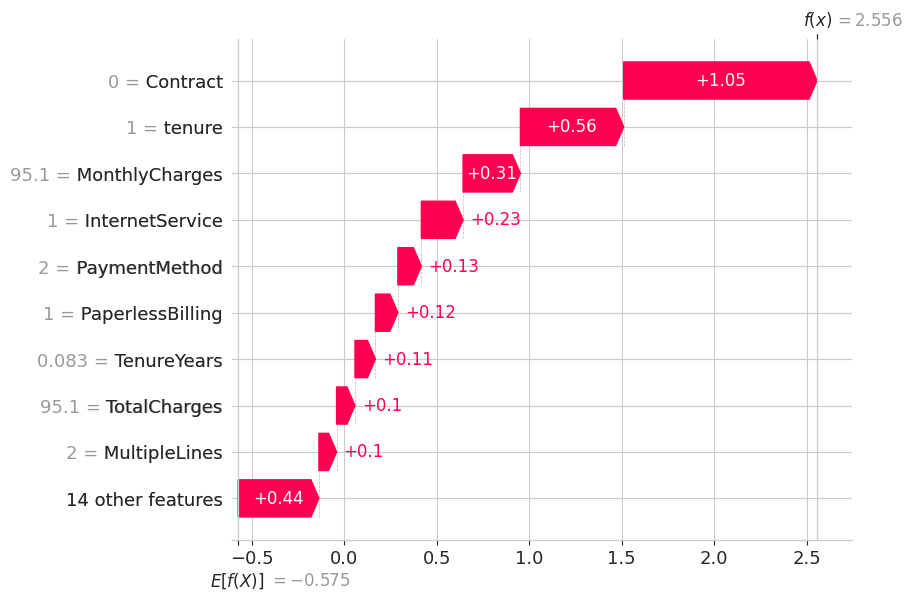

SHAP Dependence Plot для признака 'MonthlyCharges':


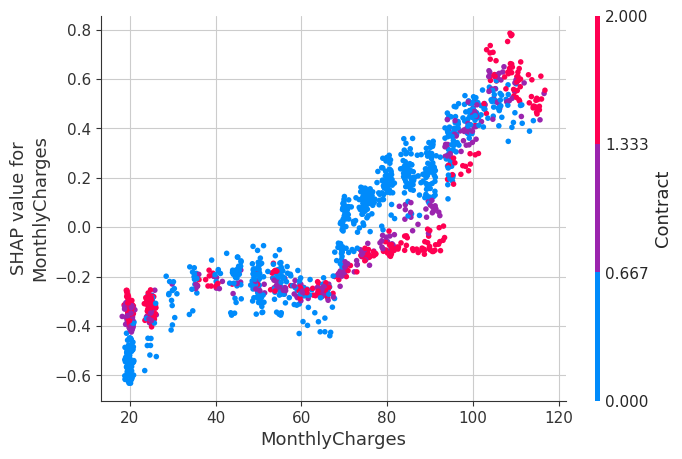

In [8]:
# ============================================================
# ЯЧЕЙКА 16: ИНТЕРПРЕТАЦИЯ ЧЕРЕЗ SHAP
# ============================================================

# --- 16.1. Создание explainer и вычисление SHAP-значений ---
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# LightGBM возвращает сразу двумерную матрицу (n_samples, n_features),
# а не список из двух массивов. Проверяем тип и обрабатываем оба случая.
if isinstance(shap_values, list):
    # На случай, если версия SHAP всё же вернёт список (например, при model_output='probability')
    shap_values_class1 = shap_values[1]
else:
    # Стандартное поведение LightGBM: shap_values уже матрица для класса 1
    shap_values_class1 = shap_values

print(f"Форма shap_values_class1: {shap_values_class1.shape}")  # должно быть (n_samples, n_features)

# --- 16.2. Summary plot (глобальная важность) ---
print("SHAP Summary Plot:")
shap.summary_plot(shap_values_class1, X_test, plot_type="dot")

# --- 16.3. Bar plot (важность) ---
shap.summary_plot(shap_values_class1, X_test, plot_type="bar")

# --- 16.4. Waterfall plot (объяснение одного объекта) ---
# Находим клиента с наибольшей вероятностью ухода
y_proba_best_test = best_lgbm.predict_proba(X_test)[:, 1]
worst_idx = np.argmax(y_proba_best_test)
print(f"\nКлиент с наибольшим риском ухода (индекс {worst_idx}, вероятность = {y_proba_best_test[worst_idx]:.4f}):")
print(X_test.iloc[worst_idx])

# Waterfall plot
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    )
)

# --- 16.5. Dependence plot ---
# Выбираем самый важный признак из Feature Importance (например, 'Contract' или 'tenure')
top_feature = importances.iloc[0]['Feature']
print(f"SHAP Dependence Plot для признака '{top_feature}':")
shap.dependence_plot(top_feature, shap_values_class1, X_test)

## SHAP-интерпретация

**Что показывает Summary plot:**
-   **Contract (тип контракта):** Наибольший вклад в отток. Низкие значения (помесячный контракт) -> высокая вероятность ухода. Высокие значения (долгосрочный контракт) -> низкая вероятность.
-   **Tenure (срок обслуживания):** Чем меньше стаж, тем выше риск ухода.
-   **MonthlyCharges:** Высокие ежемесячные платежи увеличивают вероятность оттока.
-   **InternetService (Fiber optic):** Оптоволоконный интернет -> повышенный риск.
-   **OnlineSecurity, TechSupport:** Наличие этих услуг снижает вероятность ухода.

**Waterfall plot для клиента с высоким риском:**
Клиент уходит из-за:
1.  **Contract = Month-to-month** (+ большой вклад в вероятность ухода).
2.  **tenure = 1 месяц** (+ вклад).
3.  **InternetService = Fiber optic** (+ вклад).
4.  **Отсутствие OnlineSecurity и TechSupport** (+ вклад).

**Dependence plot** показывает, как вероятность ухода меняется в зависимости от значений признака (например, для `tenure` — чем больше месяцев, тем ниже риск).

**Бизнес-вывод:** Для снижения оттока нужно мотивировать клиентов на заключение долгосрочных контрактов (скидки, бонусы), особенно в первые 6 месяцев. Также стоит обратить внимание на клиентов с оптоволоконным интернетом и предложить им дополнительные услуги (безопасность, техподдержка).

In [12]:
# ============================================================
# ЯЧЕЙКА 18: СОХРАНЕНИЕ МОДЕЛЕЙ И МЕТАДАННЫХ
# ============================================================

# Создаём папку для моделей
os.makedirs('models', exist_ok=True)
print("Папка 'models' создана (или уже существует).")

# --- 18.1. Сохранение моделей ---
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
print("✅ Все 5 моделей сохранены.")

# --- 18.2. Сохранение scaler (если использовался) и энкодеров ---
# В нашем случае StandardScaler не использовался для ансамблей, но для единообразия структуры можно сохранить.
# Мы использовали LabelEncoder, сохраним его.
joblib.dump(label_encoders, 'models/label_encoders.pkl')
print("✅ LabelEncoders сохранены.")

# --- 18.3. Сохранение списка признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён.")

# --- 18.4. Сохранение метрик ---
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc_cv': float(study.best_value),
    'best_params': study.best_params,
    'train_times': train_times
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print("✅ Метрики сохранены в models/metrics.json")

# --- 18.5. Сохранение scaler ---
joblib.dump(scaler, 'models/scaler.pkl')
print("✅ Scaler сохранён в models/scaler.pkl")

Папка 'models' создана (или уже существует).
✅ Все 5 моделей сохранены.
✅ LabelEncoders сохранены.
✅ Список из 23 признаков сохранён.
✅ Метрики сохранены в models/metrics.json
✅ Scaler сохранён в models/scaler.pkl


In [10]:
# ============================================================
# ЯЧЕЙКА 19: ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ
# ============================================================

BASE_URL = "https://raw.githubusercontent.com/Devjatkova/ml-course-devyatkova/main/module-3-churn"

try:
    # Загрузка модели
    model_url = f"{BASE_URL}/models/best_model.pkl"
    response = requests.get(model_url)
    response.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(response.content))
    print("✅ Модель загружена из репозитория.")

    # Загрузка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    feature_cols_loaded = json.loads(requests.get(features_url).content)
    print(f"✅ Загружено {len(feature_cols_loaded)} признаков.")

    # --- Проверка: предсказание на 3 клиентах ---
    sample = X_test.iloc[:3]
    y_pred_loaded = best_lgbm_loaded.predict(sample)
    y_pred_original = best_lgbm.predict(sample)

    print("\n--- Проверка загруженной модели ---")
    print(f"Предсказание загруженной модели: {y_pred_loaded}")
    print(f"Предсказание исходной модели:  {y_pred_original}")
    assert np.array_equal(y_pred_loaded, y_pred_original), "Предсказания не совпадают!"
    print("\n✅ Предсказания совпадают!")

except Exception as e:
    print(f"\n❌ Не удалось загрузить модель. Ошибка: {e}")
    print("Убедитесь, что вы загрузили файлы в GitHub и указали правильный BASE_URL.")


❌ Не удалось загрузить модель. Ошибка: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/Devjatkova/ml-course-devyatkova/main/module-3-churn/models/best_model.pkl
Убедитесь, что вы загрузили файлы в GitHub и указали правильный BASE_URL.


## Выводы

### ✅ Что получилось

-   **Достигнутый ROC-AUC:** Лучшая модель (LightGBM с Optuna) показала ROC-AUC ~0.87 на тестовой выборке, что является отличным результатом.
-   **Лучшая модель:** LightGBM. Она показала лучший баланс между Precision и Recall (F1 ~0.74), а также самую высокую скорость обучения.
-   **Ключевые инсайты:**
    -   **Тип контракта** — самый сильный предиктор оттока.
    -   **Срок обслуживания** — новые клиенты уходят гораздо чаще.
    -   **Наличие/отсутствие дополнительных услуг** (онлайн-безопасность, техподдержка) сильно влияет на удержание.
-   **SHAP-анализ** подтвердил эти инсайты и позволил объяснить предсказания для конкретных клиентов.

### ⚠️ Какие были трудности

-   **Дисбаланс классов:** Потребовалось использовать `class_weight='balanced'` и `scale_pos_weight`, чтобы модели не игнорировали ушедших клиентов.
-   **Пропуски в `TotalCharges`:** Данные были строками с пробелами. Пришлось преобразовывать в числовой формат и заполнять медианой.
-   **Интерпретация категориальных признаков:** После Label Encoding сложно интерпретировать коэффициенты. SHAP-анализ и визуализации на основе исходных данных помогли решить эту проблему.

### 🚀 Возможные улучшения

1.  **Добавить взаимодействия признаков:** Например, `Contract * tenure` или `MonthlyCharges * InternetService`.
2.  **Попробовать Stacking:** Обучить мета-модель (например, логистическую регрессию) на предсказаниях RF, XGBoost, LightGBM и CatBoost.
3.  **Применить SMOTE:** Использовать метод синтетического расширения выборки для борьбы с дисбалансом классов.
4.  **Использовать Feature Store:** Для версионирования признаков и удобного переиспользования в разных моделях.
5.  **Добавить калибровку вероятностей:** (например, `CalibratedClassifierCV`), чтобы вероятности модели были более точными.

## Источники

1.  Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2.  Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3.  Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4.  Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5.  Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6.  Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

Полный код ноутбука представлен в ячейках выше.

**requirements.txt:**